# W1D4 – Exploratory Data Analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style("whitegrid")

## 1. Load the dataset

In [6]:
data_path = Path(r"C:\Users\asus tuf a15\Desktop\Cynaris\cynaris-internship-Satish-Malladad\w1d4-eda\data\sample_dataset.csv")
df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (21675, 7)


,Date,State,Confirmed,Recovered,Deceased,Other,Tested
0,2020-01-30,Kerala,1,0,0,0,NaN
1,2020-01-30,India,1,0,0,0,NaN
2,2020-02-02,Kerala,2,0,0,0,NaN
3,2020-02-02,India,2,0,0,0,NaN
4,2020-02-03,Kerala,3,0,0,0,NaN


## 2. Inspect the dataset

In [7]:
# Information about columns and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21675 entries, 0 to 21674
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       21675 non-null  str    
 1   State      21675 non-null  str    
 2   Confirmed  21675 non-null  int64  
 3   Recovered  21675 non-null  int64  
 4   Deceased   21675 non-null  int64  
 5   Other      21675 non-null  int64  
 6   Tested     20912 non-null  float64
dtypes: float64(1), int64(4), str(2)
memory usage: 1.6 MB


In [8]:
# Summary statistics
df.describe(include="all")

,Date,State,Confirmed,Recovered,Deceased,Other,Tested
count,21675,21675,2.167500e+04,2.167500e+04,21675.000000,21675.000000,2.091200e+04
unique,613,38,NaN,NaN,NaN,NaN,NaN
top,2020-05-19,Kerala,NaN,NaN,NaN,NaN,NaN
freq,37,613,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,7.555970e+05,7.124357e+05,10139.065836,281.688028,1.260827e+07
std,NaN,NaN,3.094074e+06,2.962147e+06,41461.658802,1338.299441,4.843699e+07
min,NaN,NaN,0.000000e+00,0.000000e+00,0.000000,-1.000000,5.800000e+01
25%,NaN,NaN,6.745500e+03,4.966500e+03,56.000000,0.000000,1.861295e+05
50%,NaN,NaN,6.701600e+04,5.882300e+04,850.000000,0.000000,1.184390e+06
75%,NaN,NaN,4.799305e+05,4.012895e+05,5358.000000,4.000000,9.974060e+06


In [9]:
# Missing values in each column
df.isnull().sum()

Date           0
State          0
Confirmed      0
Recovered      0
Deceased       0
Other          0
Tested       763
dtype: int64

## 3. Check data quality

In [10]:
print("Duplicate rows:", df.duplicated().sum())

numeric_cols = df.select_dtypes(include="number").columns
print("\nNegative values in numeric columns:")
(df[numeric_cols] < 0).sum()

Duplicate rows: 0

Negative values in numeric columns:


Confirmed    0
Recovered    0
Deceased     0
Other        4
Tested       0
dtype: int64

## 4. Plot numeric distributions

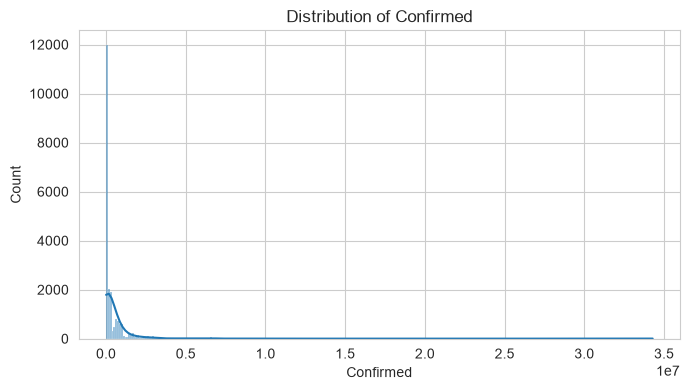

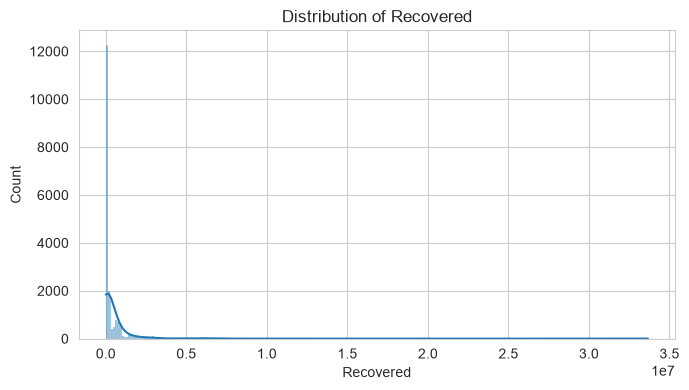

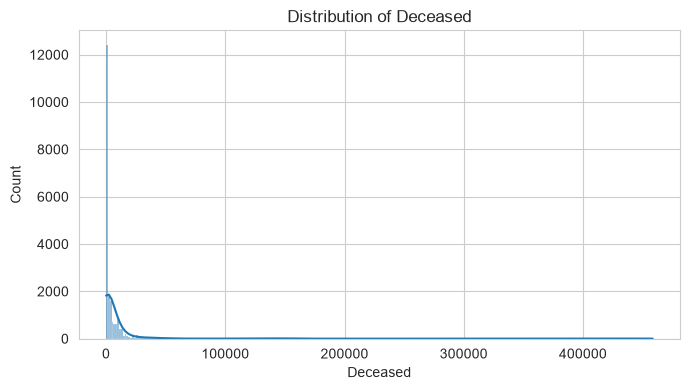

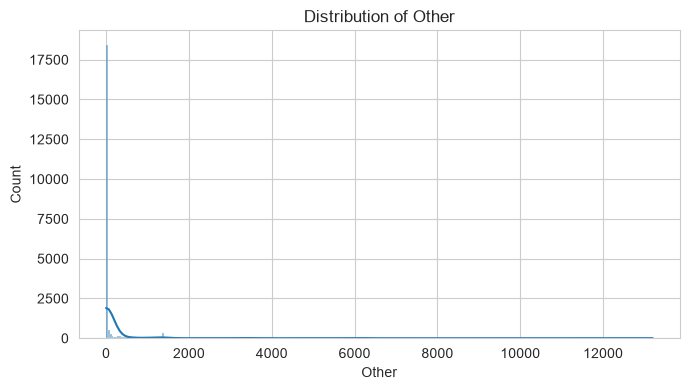

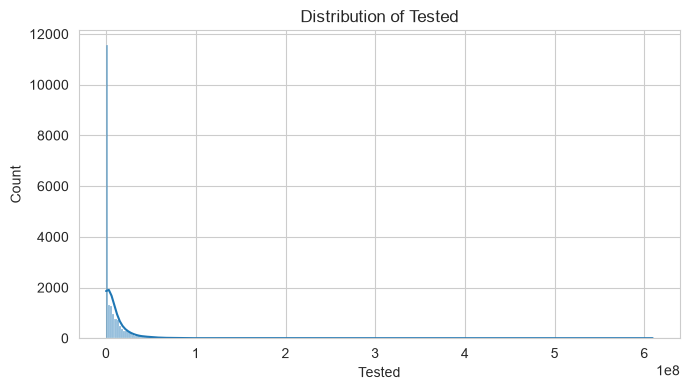

In [11]:
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

## 5. Correlation heatmap

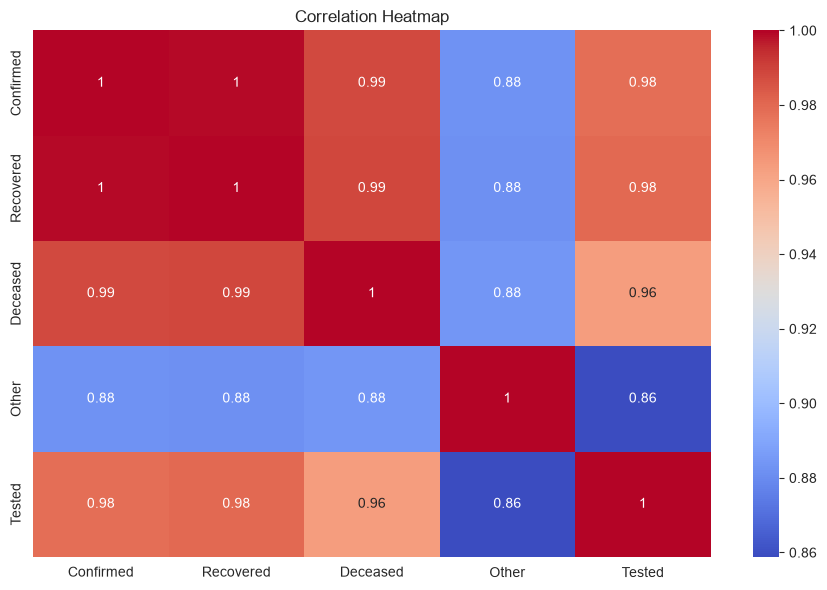

In [12]:
if len(numeric_cols) > 1:
    plt.figure(figsize=(9, 6))
    sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm")
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation heatmap.")

## 6. Top 10 values in categorical columns

C:\Users\asus tuf a15\AppData\Local\Temp\ipykernel_25524\1535877009.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_cols = df.select_dtypes(include=["object", "category"]).columns


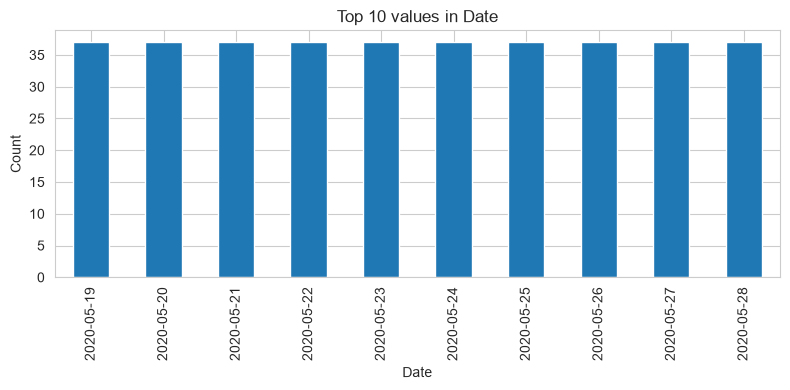

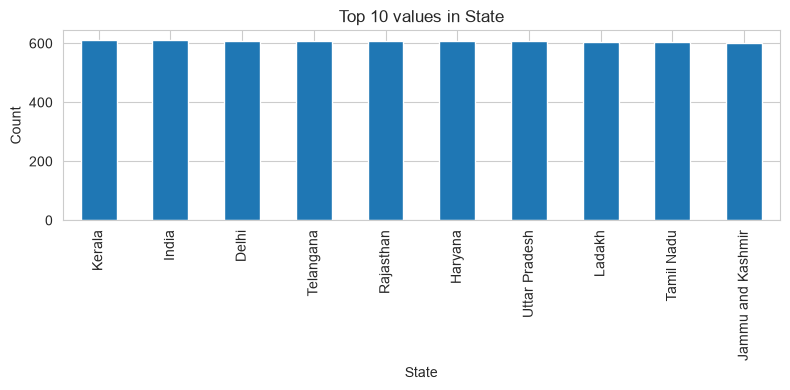

In [13]:
category_cols = df.select_dtypes(include=["object", "category"]).columns

for col in category_cols:
    counts = df[col].fillna("Missing").astype(str).value_counts().head(10)
    counts.plot(kind="bar", figsize=(8, 4), title=f"Top 10 values in {col}")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

## 7. Five observations

In [14]:
missing = df.isnull().sum()
observations = [
    f"The dataset contains {df.shape[0]} rows and {df.shape[1]} columns.",
    f"It has {len(numeric_cols)} numeric columns.",
    f"It has {len(category_cols)} categorical columns.",
    f"There are {int(missing.sum())} missing values in total.",
    f"There are {int(df.duplicated().sum())} duplicate rows."
]

for number, observation in enumerate(observations, start=1):
    print(f"{number}. {observation}")

1. The dataset contains 21675 rows and 7 columns.
2. It has 5 numeric columns.
3. It has 2 categorical columns.
4. There are 763 missing values in total.
5. There are 0 duplicate rows.


## 8. EDA narrative

The dataset contains information arranged in rows and columns, with both numeric and categorical data. I started by checking the dataset structure, data types and summary statistics to understand what kind of information it contains.

During the initial inspection, I checked for missing values and duplicate records. Missing values need attention because they can affect the results of further analysis. Duplicate records should also be reviewed to make sure the same information is not being counted more than once. I also checked for negative values to identify anything that might need further investigation.

The histograms helped me understand how the numeric values are distributed. The category charts showed which values appear most frequently, while the correlation heatmap helped identify relationships between numeric columns. These patterns give a better understanding of the dataset, although correlation does not necessarily mean that one value causes another.

Before using this data for machine learning, I would investigate unusual values, decide how to handle missing data and duplicates, and check whether any transformations are needed. I would also keep the original dataset unchanged so that the analysis can be repeated whenever required.